# Briscola — card classification
Card crops extracted from games 1-4 and from the Trentine card dataset.
Dataset downloaded from github release `dataset-v1`.

In [1]:
# --- download the dataset from the github release
import os, glob, shutil, subprocess

RELEASE = ('https://github.com/marchettialessio/BRISCOLA_project_CV'
           '/releases/download/dataset-v1')

DATASET_ZIP = 'briscola_dataset.zip'
DATASET_SIZE = 166082852          # exact size in bytes: guards against a truncated download
ROOT = '/content'
DATA_DIR = os.path.join(ROOT, 'dataset')      # images, labels and labels trentine


def ok_size(path, size):
    return os.path.isfile(path) and os.path.getsize(path) == size


def _resume_cmd(url, dst):
    """wget on Colab, curl elsewhere: both resume a partial file instead of starting over."""
    if shutil.which('wget'):
        return ['wget', '-q', '--show-progress', '-c', '-O', dst, url]
    if shutil.which('curl'):
        return ['curl', '-fL', '-#', '-C', '-', '-o', dst, url]
    raise RuntimeError('neither wget nor curl available')


def fetch(name, size, out_dir=ROOT, tries=3):
    """Download a Release asset and verify its exact size."""
    dst = os.path.join(out_dir, name)
    for k in range(tries):
        if ok_size(dst, size):
            return dst
        if os.path.isfile(dst) and os.path.getsize(dst) > size:
            os.remove(dst)        # corrupted (too large)
        r = subprocess.run(_resume_cmd(f'{RELEASE}/{name}', dst))
        got = os.path.getsize(dst) if os.path.isfile(dst) else 0
        if ok_size(dst, size):
            return dst
        print(f'  {name}: attempt {k + 1}/{tries} incomplete '
              f'({got}/{size} bytes, exit={r.returncode})')
    raise RuntimeError(f'{name}: download failed, re-run the cell (the partial file will be resumed)')


if not os.path.isdir(os.path.join(DATA_DIR, 'images')):
    z = fetch(DATASET_ZIP, DATASET_SIZE)
    !unzip -q -o "{z}" -d "{DATA_DIR}"

assert os.path.isdir(os.path.join(DATA_DIR, 'images')), 'dataset not found after download'
print('Images:', len(os.listdir(os.path.join(DATA_DIR, 'images'))))

Images: 1419


## LOADING CSV
`class_id = suit*10 + (rank - 1)`, rank 1-10, suit 0-3 = coins, cups, spades, clubs (as in `DatasetUtils.hpp`).
The crop filename is `g{game}_r{round}_{north|south}_f{frame}.png`; Trentine scans have `game = 0`.

In [2]:
import numpy as np
import pandas as pd

NUM_CLASSES = 40
GAMES = [1, 2, 3, 4]

def load_labels(data_dir):
    frames = []
    for g in GAMES:
        df = pd.read_csv(os.path.join(data_dir, f'labels_game{g}.csv'))
        df['game'] = g
        df['round'] = df['filename'].str.extract(r'_r(\d+)_')[0].astype(int)
        frames.append(df)

    # Trentine scans
    tr = pd.read_csv(os.path.join(data_dir, 'labels_trentine.csv'))
    tr['game'] = 0
    tr['round'] = 0
    frames.append(tr)

    # concat all the dataframes
    df = pd.concat(frames, ignore_index=True)
    # complete path of the corresponding image
    df['path'] = df['filename'].map(lambda f: os.path.join(data_dir, 'images', f))
    return df


labels = load_labels(DATA_DIR)

# I want to check if al the paths are correct and if the class is correct
assert labels['path'].map(os.path.isfile).all(), 'images missing with respect to the CSVs'
assert labels['class_id'].between(0, NUM_CLASSES - 1).all()

print(labels.groupby('game').agg(images=('filename', 'size'), classes=('class_id', 'nunique')))

      images  classes
game                 
0         40       40
1        590       40
2        284       40
3        182       36
4        323       30


## GENERATING THE 4 FOLDS (leave-one-game-out)
- **Test** fold k = all of game k, no data leak.
- **Val** = whole rounds from training games. Selecting single frames is not appropriate, since frames from the same round are similar (val train data leak).
- **Train** = rest of the training games + the 40 Trentine scans.

In [3]:
VAL_ROUNDS = 3 #how many round to do validation on
SEED = 100


def make_folds(df, val_rounds=VAL_ROUNDS, seed=SEED):
    rng = np.random.default_rng(seed)
    folds = []
    for test_game in GAMES:
        # default: train
        split = pd.Series('train', index=df.index)
        # overwrite with test only correct rows
        split[df['game'] == test_game] = 'test'

        # val: rounds drawn at random from each training game
        for g in GAMES:
            if g == test_game:
                continue
            rounds = np.sort(df.loc[df['game'] == g, 'round'].unique())
            val = rng.choice(rounds, size=val_rounds, replace=False)
            # overwrite with val only correct rows
            split[(df['game'] == g) & df['round'].isin(val)] = 'val'

        # new dataset with column split added
        fold = df.assign(split=split)
        folds.append(fold)
    return folds


folds = make_folds(labels)

for k, fold in enumerate(folds, start=1):
    print(f'fold {k}:', fold['split'].value_counts().to_dict())

fold 1: {'train': 720, 'test': 590, 'val': 109}
fold 2: {'train': 985, 'test': 284, 'val': 150}
fold 3: {'train': 1041, 'val': 196, 'test': 182}
fold 4: {'train': 916, 'test': 323, 'val': 180}


## DATA AUGMENTATION
The objective of the trasformations is to reproduce a variation seen on video crops

In [4]:
import random
import torch
from PIL import Image
from torchvision import models, transforms

IMG_H, IMG_W = 192, 128          # 300x200 crops downscaled keeping the 3:2 ratio

# the pretrained ResNet18 was trained with this normalization, our input must use the same one
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
MEAN = WEIGHTS.transforms().mean
STD = WEIGHTS.transforms().std

random.seed(SEED)
torch.manual_seed(SEED)


class RandomRotate180(object):

    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img
        return img.rotate(180)


class RandomColorCast(object):
    # simulates a different white balance
    def __init__(self, max_gain=0.2, p=0.5):
        self.max_gain = max_gain
        self.p = p

    def __call__(self, x):
        if random.random() > self.p:
            return x
        gain = 1 + (torch.rand(3, 1, 1) * 2 - 1) * self.max_gain
        return (x * gain).clamp(0, 1)


def make_transforms(mean, std):
    train_transform = transforms.Compose([
        transforms.Resize((IMG_H, IMG_W)),
        RandomRotate180(p=0.5),
        transforms.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.9, 1.1)),
        transforms.RandomPerspective(distortion_scale=0.1, p=0.3),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
        transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
        transforms.ToTensor(),
        RandomColorCast(max_gain=0.2, p=0.5),
        transforms.Normalize(mean, std),
        transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
    ])

    eval_transform = transforms.Compose([
        transforms.Resize((IMG_H, IMG_W)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    return train_transform, eval_transform

## DATASET AND DATALOADER
In the training set game1 has up to 44 crops per card, game3 as few as 3, and each Trentine scan is a single image.
With `balanced=True` a `WeightedRandomSampler` gives **the same weight to every played card** `(game, round, class_id)`
and to every Trentine scan, so the model does not mostly learn the game1 conditions.

In [5]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

BATCH_SIZE = 32
NUM_WORKERS = 2


class CardDataset(Dataset):
    """Returns (x, class_id)."""
    def __init__(self, df, transform):
        self.paths = df['path'].tolist()
        self.labels = df['class_id'].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        x = self.transform(img)
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        return x, y


def card_weights(df):
    n = df.groupby(['game', 'round', 'class_id'])['path'].transform('size')
    return torch.as_tensor(1.0 / n.values, dtype=torch.double)


def make_dataloaders(fold, mean, std, batch_size=BATCH_SIZE, balanced=True):
    train, val, test = (fold[fold['split'] == s] for s in ['train', 'val', 'test'])
    train_transform, eval_transform = make_transforms(mean, std)
    g = torch.Generator().manual_seed(SEED)
    train_ds = CardDataset(train, train_transform)
    if balanced:
        sampler = WeightedRandomSampler(card_weights(train), num_samples=len(train), replacement=True, generator=g)
        train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler, num_workers=NUM_WORKERS)
    else:
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g, num_workers=NUM_WORKERS)

    # val/test: no augmentation and no shuffle
    val_loader = DataLoader(CardDataset(val, eval_transform), batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(CardDataset(test, eval_transform), batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader, test_loader

## VISUAL CHECK OF THE AUGMENTATION
One training batch of fold 1, denormalized.

batch: (32, 3, 192, 128) | distinct classes in the batch: 21


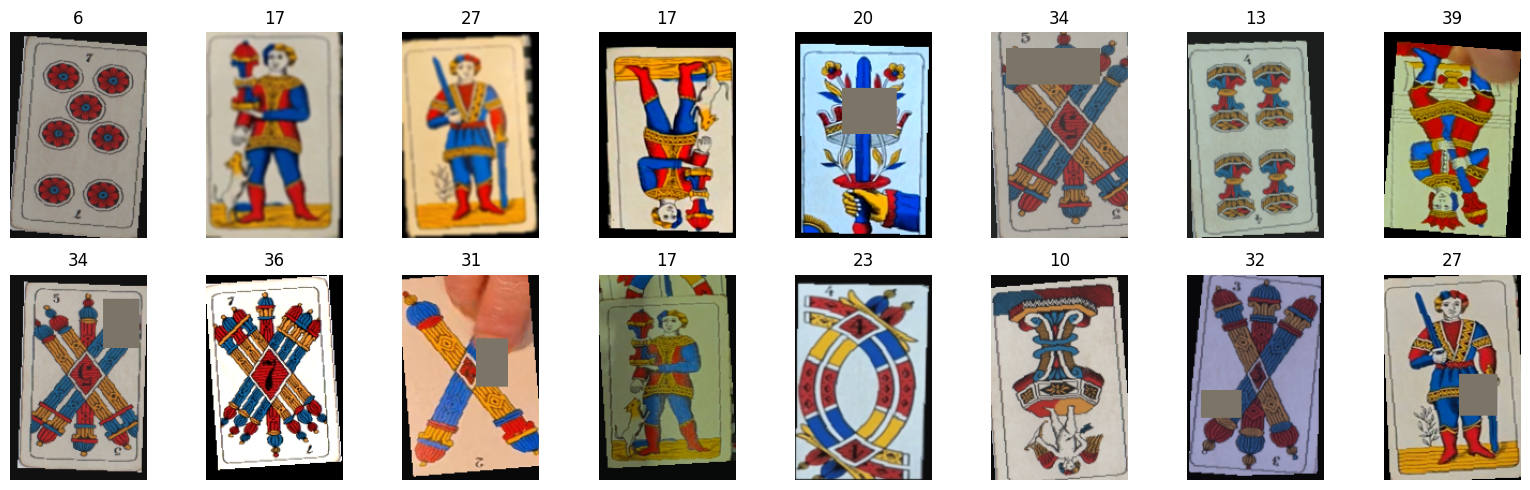

In [6]:
import matplotlib.pyplot as plt

fold = folds[0]
train_loader, val_loader, test_loader = make_dataloaders(fold, MEAN, STD)
x, y = next(iter(train_loader))
print('batch:', tuple(x.shape), '| distinct classes in the batch:', y.unique().numel())

img = x[:16] * torch.tensor(STD).view(1, 3, 1, 1) + torch.tensor(MEAN).view(1, 3, 1, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, im, lab in zip(axes.flat, img, y):
    ax.imshow(im.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(int(lab))
    ax.axis('off')
plt.tight_layout()
plt.show()

## MODEL
ResNet18 pretrained on ImageNet (torchvision), the last layer is replaced with a linear layer with 40 outputs.

In [7]:
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def build_model():
    model = models.resnet18(weights=WEIGHTS)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


def set_backbone_trainable(model, trainable):
    # every layer except the final fc
    for name, param in model.named_parameters():
        if not name.startswith('fc.'):
            param.requires_grad = trainable

## TRAINING
Two phases:
1. backbone frozen, only the new fc layer is trained: it starts random, and its large initial gradients would damage the pretrained features;
2. the whole network is unfrozen, with a lower learning rate on the backbone than on the fc layer.

The weights with the lowest validation loss are kept, then evaluated on the test game.

In [8]:
import copy

HEAD_EPOCHS = 5
FINETUNE_EPOCHS = 15
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4


def run_epoch(model, loader, criterion, optimizer=None):
    # train if an optimizer is given, otherwise only evaluate
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(dim=1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def train_fold(fold):
    train_loader, val_loader, test_loader = make_dataloaders(fold, MEAN, STD)
    model = build_model().to(device)
    criterion = nn.CrossEntropyLoss()

    # phase 1: only the fc layer
    set_backbone_trainable(model, False)
    head_optimizer = torch.optim.Adam(model.fc.parameters(), lr=HEAD_LR)

    # phase 2: whole network, smaller steps on the pretrained layers
    backbone_params = [p for name, p in model.named_parameters() if not name.startswith('fc.')]
    finetune_optimizer = torch.optim.Adam([{'params': backbone_params, 'lr': BACKBONE_LR},
                                           {'params': model.fc.parameters(), 'lr': HEAD_LR}])

    best_loss, best_state = float('inf'), None
    for epoch in range(HEAD_EPOCHS + FINETUNE_EPOCHS):
        if epoch < HEAD_EPOCHS:
            optimizer = head_optimizer
        else:
            set_backbone_trainable(model, True)
            optimizer = finetune_optimizer

        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        print(f'epoch {epoch + 1:2d} | train loss {train_loss:.3f} acc {train_acc:.3f} | val loss {val_loss:.3f} acc {val_acc:.3f}')

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test_loss, test_acc = run_epoch(model, test_loader, criterion)
    return model, test_acc

## 4-FOLD CROSS VALIDATION
Test accuracy is per crop; the per-card accuracy of the project is computed in C++.

In [ ]:
test_accs = []
fold_models = []
for k, fold in enumerate(folds, start=1):
    print(f'\n===== fold {k} (test = game {k}) =====')
    model, test_acc = train_fold(fold)
    fold_models.append(model)
    test_accs.append(test_acc)
    print(f'test accuracy game {k}: {test_acc:.3f}')

print('\ntest accuracy per fold:', [round(a, 3) for a in test_accs])
print(f'mean: {np.mean(test_accs):.3f}')


===== fold 1 (test = game 1) =====
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 206MB/s]


epoch  1 | train loss 3.272 acc 0.197 | val loss 2.868 acc 0.266
epoch  2 | train loss 2.155 acc 0.469 | val loss 1.589 acc 0.587
epoch  3 | train loss 1.554 acc 0.647 | val loss 1.014 acc 0.725
epoch  4 | train loss 1.130 acc 0.797 | val loss 0.857 acc 0.780
epoch  5 | train loss 0.954 acc 0.821 | val loss 0.657 acc 0.771
epoch  6 | train loss 0.564 acc 0.871 | val loss 0.220 acc 0.963
epoch  7 | train loss 0.196 acc 0.947 | val loss 0.110 acc 0.991
epoch  8 | train loss 0.087 acc 0.972 | val loss 0.090 acc 0.991
epoch  9 | train loss 0.054 acc 0.989 | val loss 0.093 acc 0.991
epoch 10 | train loss 0.042 acc 0.988 | val loss 0.150 acc 0.982
epoch 11 | train loss 0.074 acc 0.974 | val loss 0.188 acc 0.936
epoch 12 | train loss 0.047 acc 0.989 | val loss 0.120 acc 0.972
epoch 13 | train loss 0.030 acc 0.990 | val loss 0.102 acc 0.991
epoch 14 | train loss 0.039 acc 0.992 | val loss 0.101 acc 0.972
epoch 15 | train loss 0.024 acc 0.994 | val loss 0.097 acc 0.991
epoch 16 | train loss 0.0

## SAVE THE MODELS
One model per fold: in C++ game k must be analysed with the model of fold k, the only one that never saw game k during training.
- `resnet18_fold{k}.torch`: PyTorch checkpoint, to reload the model in Python;
- `resnet18_fold{k}.onnx`: model for `cv::dnn::readNetFromONNX` in C++.

C++ preprocessing must match `eval_transform`: RGB (not BGR), resize to `IMG_W x IMG_H`, pixel / 255, then `(x - MEAN) / STD`.

In [ ]:
!pip -q install onnx

# --- checkpoint dir; USE_OWN_DRIVE=True keeps the files after the Colab session ends
USE_OWN_DRIVE = False

if USE_OWN_DRIVE:
    from google.colab import drive
    if not os.path.ismount('/content/drive'):
        drive.mount('/content/drive')
    CKPT_DIR = '/content/drive/MyDrive/Briscola_checkpoints'
else:
    CKPT_DIR = os.path.join(ROOT, 'Briscola_checkpoints')
os.makedirs(CKPT_DIR, exist_ok=True)


def ckpt_path(name):
    return os.path.join(CKPT_DIR, name)


for k, (model, test_acc) in enumerate(zip(fold_models, test_accs), start=1):
    model = model.cpu().eval()
    torch.save({'model_state_dict': model.state_dict(),
                'fold': k, 'test_acc': test_acc,
                'img_size': (IMG_H, IMG_W), 'mean': MEAN, 'std': STD}, ckpt_path(f'resnet18_fold{k}.torch'))

    # dynamic batch: in C++ all the crops of a card can go through the network in one forward
    dummy = torch.zeros(1, 3, IMG_H, IMG_W)
    torch.onnx.export(model, dummy, ckpt_path(f'resnet18_fold{k}.onnx'), dynamo=False,
                      input_names=['input'], output_names=['logits'],
                      dynamic_axes={'input': {0: 'batch'}, 'logits': {0: 'batch'}})

print('Checkpoint dir:', CKPT_DIR)
for n in sorted(os.listdir(CKPT_DIR)):
    print(f'  {n:24s} {os.path.getsize(ckpt_path(n)) / 1e6:6.1f} MB')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 68.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 23.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.


NameError: name 'fold_models' is not defined

## ONNX CHECK WITH OPENCV
The ONNX model read by OpenCV must give the same output as PyTorch on the test images of the fold.

In [ ]:
import cv2

for k, (model, fold) in enumerate(zip(fold_models, folds), start=1):
    net = cv2.dnn.readNetFromONNX(ckpt_path(f'resnet18_fold{k}.onnx'))
    _, _, test_loader = make_dataloaders(fold, MEAN, STD)
    x, y = next(iter(test_loader))

    net.setInput(x.numpy())
    out_cv = net.forward()
    with torch.no_grad():
        out_torch = model.cpu().eval()(x).numpy()

    same = (out_cv.argmax(axis=1) == out_torch.argmax(axis=1)).mean()
    print(f'fold {k}: max diff {np.abs(out_cv - out_torch).max():.2e} | same prediction {same:.3f}')

## UPLOAD THE MODELS TO THE GITHUB RELEASE
Needs a GitHub token with **Contents: read and write** permission on the repo, saved in the Colab secrets
(key icon on the left) with name `GITHUB_TOKEN` and notebook access enabled. The token is never written in the notebook.
Files already in the release with the same name are replaced.

In [ ]:
import requests

UPLOAD_TO_RELEASE = True
REPO = 'marchettialessio/BRISCOLA_project_CV'
MODELS_TAG = 'models-v1'
API = f'https://api.github.com/repos/{REPO}'

if UPLOAD_TO_RELEASE:
    from google.colab import userdata
    token = userdata.get('GITHUB_TOKEN')
    headers = {'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'}

    # release of the tag, created if it does not exist yet
    r = requests.get(f'{API}/releases/tags/{MODELS_TAG}', headers=headers)
    if r.status_code == 404:
        r = requests.post(f'{API}/releases', headers=headers, json={'tag_name': MODELS_TAG, 'name': MODELS_TAG})
    r.raise_for_status()
    release = r.json()

    for name in sorted(os.listdir(CKPT_DIR)):
        # an asset cannot be overwritten: the old one with the same name is deleted first
        for asset in release['assets']:
            if asset['name'] == name:
                requests.delete(f'{API}/releases/assets/{asset["id"]}', headers=headers).raise_for_status()

        with open(ckpt_path(name), 'rb') as f:
            r = requests.post(f'https://uploads.github.com/repos/{REPO}/releases/{release["id"]}/assets',
                              headers={**headers, 'Content-Type': 'application/octet-stream'},
                              params={'name': name}, data=f)
        r.raise_for_status()
        print(f'  {name}: uploaded ({os.path.getsize(ckpt_path(name)) / 1e6:.1f} MB)')

    print('Release:', release['html_url'])